# Name: Aleeha Aiman
# Rollno: 23-NTU-CS-1243
# Class: Bs Cs 7th(A)

TASK 1: Voting Classifier

In [5]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


digits = load_digits()
X, y = digits.data, digits.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

log_clf = LogisticRegression(max_iter=1000)
rnd_clf = RandomForestClassifier(random_state=42)
svm_clf = SVC()

voting_clf = VotingClassifier(
    estimators=[('lr', log_clf), ('rf', rnd_clf), ('svc', svm_clf)],
    voting='hard'
)

for clf in (log_clf, rnd_clf, svm_clf, voting_clf):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(type(clf).__name__, accuracy_score(y_test, y_pred))

some_digit = X_test[0]
print("Predicted digit:", voting_clf.predict([some_digit]))
print("Actual digit:", y_test[0])

LogisticRegression 0.975
RandomForestClassifier 0.9722222222222222
SVC 0.9861111111111112
VotingClassifier 0.9805555555555555
Predicted digit: [6]
Actual digit: 6


Task2: SVM

In [4]:
from sklearn.svm import SVC
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
import warnings
warnings.filterwarnings("ignore")


df = pd.read_csv('/content/income_evaluation.csv')
df.head()

categorical_features = df.select_dtypes(include=['object']).columns
numerical_features = df.select_dtypes(exclude=['object']).columns

df = pd.get_dummies(df, columns=categorical_features, drop_first=True)

X = df.drop("income_ >50K", axis=1)
y = df["income_ >50K"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

scaler = StandardScaler()
X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test[numerical_features] = scaler.transform(X_test[numerical_features])
display(X_train.head())

svc = SVC(random_state=101)
svc.fit(X_train,y_train)
accuracies = cross_val_score(svc,X_train,y_train,cv=5)
print("Train Score:", np.mean(accuracies))
print("Test Score:", svc.score(X_test,y_test))

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Private,workclass_ Self-emp-inc,...,native-country_ Portugal,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia
4400,-0.996110,-0.550200,-1.222152,-0.147881,-0.221529,-2.351924,False,False,True,False,...,False,False,False,False,False,False,False,True,False,False
2598,0.181302,-0.077999,-0.427479,-0.147881,-0.221529,0.791095,False,False,True,False,...,False,False,False,False,False,False,False,True,False,False
496,-1.364051,0.666475,-0.030143,-0.147881,-0.221529,-0.036015,False,False,True,False,...,False,False,False,False,False,False,False,True,False,False
4915,-1.511228,-0.028649,-1.222152,-0.147881,-0.221529,-1.690236,False,False,True,False,...,False,False,False,False,False,False,False,True,False,False
1341,1.358714,-0.955980,1.559203,-0.147881,-0.221529,-0.036015,False,False,True,False,...,False,False,False,False,False,False,False,True,False,False


Train Score: 0.8461355529131985
Test Score: 0.8488593155893536


Task3: K Means Clustring

Dataset Preview:
  cap-shape cap-surface cap-color bruises odor gill-attachment gill-spacing  \
0         x           s         n       t    p               f            c   
1         x           s         y       t    a               f            c   
2         b           s         w       t    l               f            c   
3         x           y         w       t    p               f            c   
4         x           s         g       f    n               f            w   

  gill-size gill-color stalk-shape  ... stalk-surface-below-ring  \
0         n          k           e  ...                        s   
1         b          k           e  ...                        s   
2         b          n           e  ...                        s   
3         n          n           e  ...                        s   
4         b          k           t  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w   

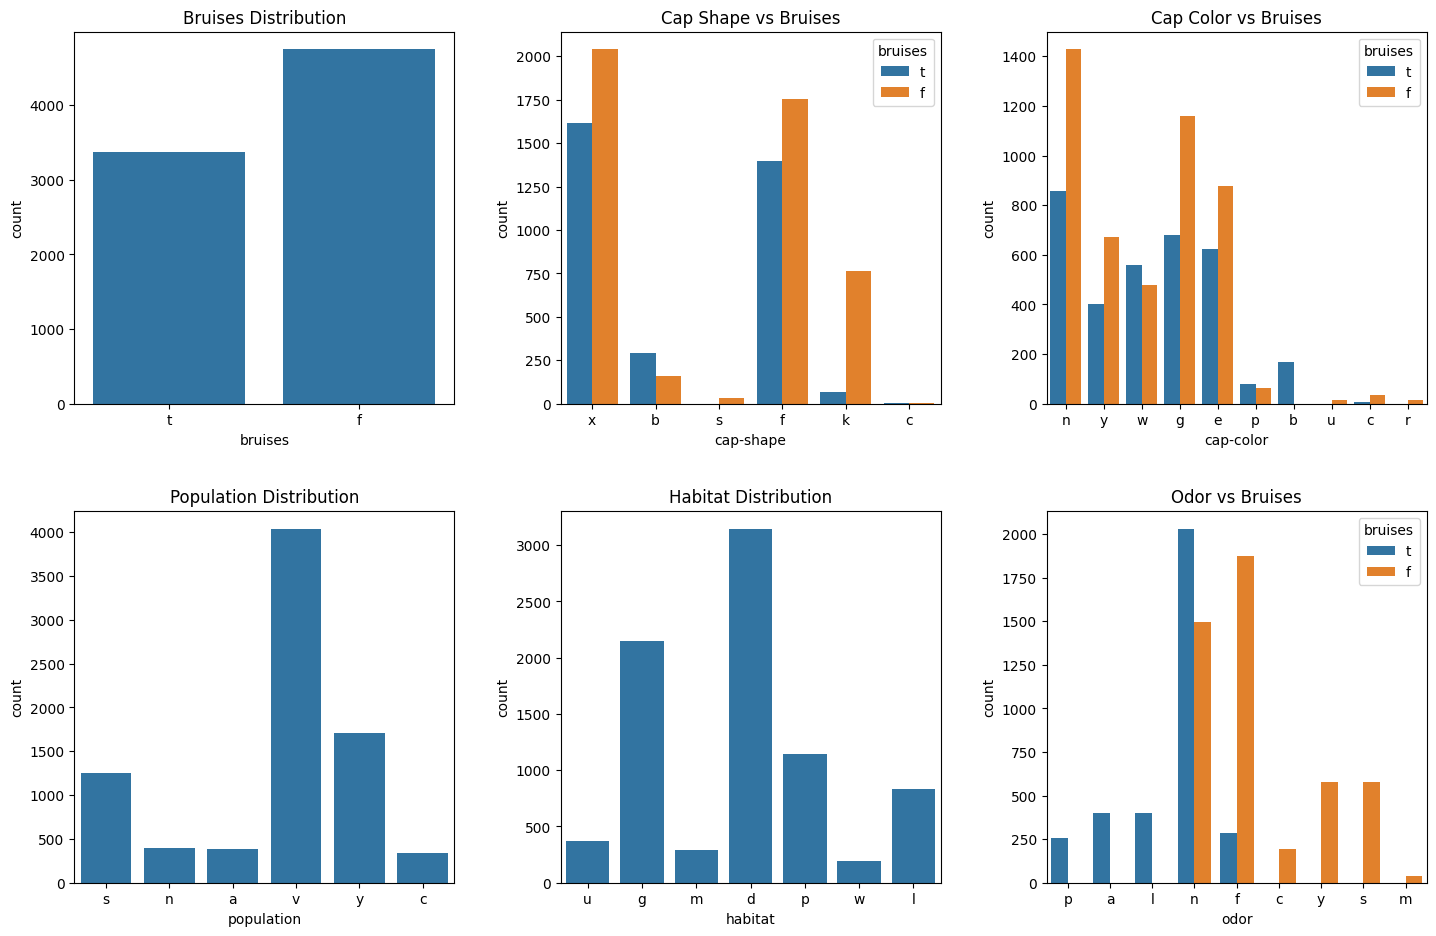

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#1. Load the dataset
mushroom_data = pd.read_csv("/content/mushroomss.csv")

# Display first few rows
print("Dataset Preview:")
print(mushroom_data.head())

#2. Check for missing values
print("\nMissing Values in Each Column:")
print(mushroom_data.isnull().sum())

print(f"Dataset shape: {mushroom_data.shape}")

# Note: the dataset has no 'class' column, so 'bruises' is used instead
print(f"Bruises distribution:\n{mushroom_data['bruises'].value_counts()}")

#3. Visualize the data
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
sns.countplot(data=mushroom_data, x='bruises')
plt.title('Bruises Distribution')

plt.subplot(2, 3, 2)
sns.countplot(data=mushroom_data, x='cap-shape', hue='bruises')
plt.title('Cap Shape vs Bruises')

plt.subplot(2, 3, 3)
sns.countplot(data=mushroom_data, x='cap-color', hue='bruises')
plt.title('Cap Color vs Bruises')

plt.subplot(2, 3, 4)
sns.countplot(data=mushroom_data, x='population')
plt.title('Population Distribution')

plt.subplot(2, 3, 5)
sns.countplot(data=mushroom_data, x='habitat')
plt.title('Habitat Distribution')

plt.subplot(2, 3, 6)
sns.countplot(data=mushroom_data, x='odor', hue='bruises')
plt.title('Odor vs Bruises')

plt.tight_layout(pad=3)
plt.show()

KMeans Accuracy: 0.3737


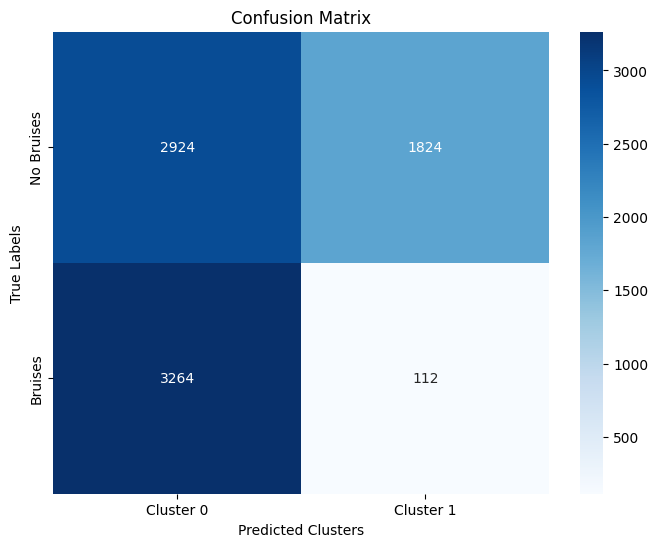


Classification Report:
              precision    recall  f1-score   support

  No Bruises       0.47      0.62      0.53      4748
     Bruises       0.06      0.03      0.04      3376

    accuracy                           0.37      8124
   macro avg       0.27      0.32      0.29      8124
weighted avg       0.30      0.37      0.33      8124



In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

mushroom_data = pd.read_csv("/content/mushroomss.csv")

mushroom_df = mushroom_data.dropna()

mushroom_features = mushroom_df.drop('bruises', axis=1)
mushroom_labels = mushroom_df['bruises']

encoder = OrdinalEncoder()
mushroom_prepared = encoder.fit_transform(mushroom_features)
mushroom_prep_df = pd.DataFrame(mushroom_prepared, columns=mushroom_features.columns)

k_clust = KMeans(n_clusters=2, random_state=42)
k_clust.fit(mushroom_prep_df)

k_labels = k_clust.labels_

map_dict = {'f': 0, 't': 1}
true_labels = mushroom_labels.map(map_dict)

accuracy = accuracy_score(true_labels, k_labels)
print(f"KMeans Accuracy: {accuracy:.4f}")

plt.figure(figsize=(8, 6))

cm = confusion_matrix(true_labels, k_labels)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cluster 0', 'Cluster 1'],
            yticklabels=['No Bruises', 'Bruises'])

plt.title('Confusion Matrix')
plt.xlabel('Predicted Clusters')
plt.ylabel('True Labels')
plt.show()

print("\nClassification Report:")
print(classification_report(true_labels, k_labels, target_names=['No Bruises', 'Bruises']))